# Normalizing Flows
## Configurations and initializations

This section loads libraries and configurations for various tasks for this course

In [1]:
## Standard libraries
import os
import math
import numpy as np
import pandas as pd
from collections import defaultdict

## Imports for plotting
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
%matplotlib inline
from IPython.display import set_matplotlib_formats
%config InlineBackend.figure_formats = ['svg', 'pdf']
from matplotlib.colors import to_rgb
import seaborn as sns

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim

# Torchvision
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "../data"

# Path to the folder where the models are saved
CHECKPOINT_PATH = "./"

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Fetching the device that will be used throughout this notebook
device = torch.device("cpu") if not torch.cuda.is_available() else torch.device("cuda:0")
print("Using device", device)

Using device cuda:0


<Figure size 640x480 with 0 Axes>

In [2]:
# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x+torch.rand_like(x) / 256)])# Implement by instructions])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)

train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, pin_memory=True, num_workers=0)
val_loader = data.DataLoader(val_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)
test_loader = data.DataLoader(test_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)

print('Train size:', len(train_loader.dataset))
print('Validation size:', len(val_loader.dataset))
print('Test size:', len(test_loader.dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 507kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.7MB/s]

Train size: 50000
Validation size: 10000
Test size: 10000


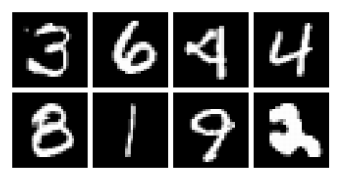

In [3]:
def show_imgs(imgs):
    num_imgs = imgs.shape[0] if isinstance(imgs, torch.Tensor) else len(imgs)
    nrow = min(num_imgs, 4)
    ncol = int(math.ceil(num_imgs/nrow))
    imgs = torchvision.utils.make_grid(imgs, nrow=nrow, pad_value=128)
    imgs = imgs.clamp(min=0, max=1)
    np_imgs = imgs.cpu().numpy()
    plt.figure(figsize=(1.5*nrow, 1.5*ncol))
    plt.imshow(np.transpose(np_imgs, (1,2,0)), interpolation='nearest')
    plt.axis('off')
    plt.show()

show_imgs([train_set[i][0] for i in range(8)])

In [4]:
# Part 1: Normalizing Flow on MNIST
from re import X
# from _typeshed import Self
# simple feed-forward neural network with 5 layers and tanh at the end
class MLP(nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim):
    super().__init__()

    self.net = nn.Sequential(
        nn.Linear(input_dim, hidden_dim), nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
        nn.Linear(hidden_dim, output_dim), nn.Tanh(), # last layer allows negative values
    )

  def forward(self, x):
    return self.net(x)

# Affine Coupling Layer
class AffineCoupling(nn.Module):
  def __init__(self, dim, hidden_dim):
    super().__init__()
    self.s_net = MLP(dim//2, hidden_dim, dim//2)
    self.t_net = MLP(dim//2, hidden_dim, dim//2)

  def forward(self, x, flip=False):
    if flip:
      x2, x1 = x.chunk(2, dim=1)
    else:
      x1, x2 = x.chunk(2, dim=1)

    s = self.s_net(x1)
    t = self.t_net(x1)
    y2 = x2 * torch.exp(s) + t
    log_det = s.sum(dim=1)

    if flip:
      return torch.cat([y2, x1], dim=1), log_det
    else:
      return torch.cat([x1, y2], dim=1), log_det

  def inverse(self, y, flip=False):
    if flip:
      y2, y1 = y.chunk(2, dim=1)
    else:
      y1, y2 = y.chunk(2, dim=1)

    s = self.s_net(y1)
    t = self.t_net(y1)
    x2 = (y2 - t) * torch.exp(-s)

    if flip:
      return torch.cat([x2, y1], dim=1)
    else:
      return torch.cat([y1, x2], dim=1)


# full normalizing flow model
class NormalizingFlow(nn.Module):
  def __init__(self, dim=784, hidden_dim=512, num_layers=6):
    super().__init__()
    self.layers = nn.ModuleList([AffineCoupling(dim, hidden_dim) for _ in range(num_layers)])
    self.flips = [i % 2 == 1 for i in range(num_layers)]
    self.logs = defaultdict(list)

  def log(self, key, value):
    self.logs[key].append(value)

  def forward(self, x):
    log_det = 0
    for layer, flip in zip(self.layers, self.flips):
      x, l = layer(x, flip)
      log_det += l
    return x, log_det

  def inverse(self, y, return_all=False):  # if return_all=True, return intermediate outputs too
      outputs = []  # to store intermediate results
      current = y  # start from z (latent)

      for layer, flip in zip(reversed(self.layers), reversed(self.flips)):  # go backward through layers
          current = layer.inverse(current, flip)  # apply one inverse layer
          if return_all:
              outputs.append(current.clone())  # save output after this layer

      if return_all:
          return outputs[::-1]  # return from z to x order
      return current  # return only final x


  def calc_nll(self, x):
    x = x.view(x.size(0), -1)
    z, log_det = self.forward(x)
    log_pz = -0.5 * (z ** 2).sum(dim=1) - 0.5 * x.shape[1] * math.log(2 * math.pi)
    return -(log_pz + log_det).mean()

  def training_step(self, x):
    loss = self.calc_nll(x)
    self.log('train_nll', loss)
    return loss

  @torch.no_grad()
  def validation_step(self, loader):
    self.eval()
    losses = []
    for x, _ in tqdm(loader, leave=False):
      x = x.to(device)
      loss = self.calc_nll(x)
      losses.append(loss.item())
    val_loss = np.mean(losses)
    self.logs['val_loss'].append(val_loss)
    return val_loss


  @torch.no_grad()
  def test_step(self, loader):
    self.eval()
    losses = []
    for x, _ in tqdm(loader, leave=False):
      x = x.to(device)
      loss = self.calc_nll(x)
      losses.append(loss.item())
    test_loss = np.mean(losses)
    self.logs['test_loss'].append(test_loss)
    return test_loss

## Model Training

In [7]:
model = NormalizingFlow(dim=784, hidden_dim=1024, num_layers=6).to(device)
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))

model = torch.compile(model.to(device))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, 1, gamma=0.99)
epochs = 60

Num params: 47,436,384


In [8]:
# Training loop
for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, _ in tqdm(train_loader, leave=False):
        imgs = imgs.to(device).view(imgs.size(0), -1) # flatten to vector
        optimizer.zero_grad()
        loss = model.training_step(imgs)
        loss.backward()
        optimizer.step()

    val_loss = model.validation_step(val_loader)
    print(f"[epoch: {epoch+1}] val loss: {val_loss:.4f}")
    scheduler.step()

# Part 2: Sampling and Visualizations
@torch.no_grad()
def sample(model, num_samples=16):
    model.eval()
    z = torch.randn(num_samples, 784).to(device)
    x_gen = model.inverse(z)
    x_gen = x_gen.view(-1, 1, 28, 28).clamp(0, 1)
    show_imgs(x_gen)


@torch.no_grad()
def visualize_flow_transforms(model, num_samples=10):
    model.eval()
    z = torch.randn(num_samples, 784).to(device)  # generate 10 samples from latent space

    all_transforms = []  # list to store all rows of 5 images

    for i in range(num_samples):
        z_i = z[i].unsqueeze(0)  # shape (1, 784)
        outputs = model.inverse(z_i, return_all=True)  # get all intermediate outputs through flow
        selected = outputs[:5]  # keep only first 5 steps
        row = torch.cat(selected, dim=0)  # put 5 images in a row
        all_transforms.append(row)

    # create final image grid (10 rows × 5 columns)
    grid_imgs = torch.cat(all_transforms, dim=0).view(-1, 1, 28, 28).clamp(0, 1)
    show_imgs(grid_imgs)


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

[epoch: 1] val loss: -1036.7808


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

...

  0%|          | 0/79 [00:00<?, ?it/s]

[epoch: 59] val loss: -1274.5844


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

[epoch: 60] val loss: -1276.8893


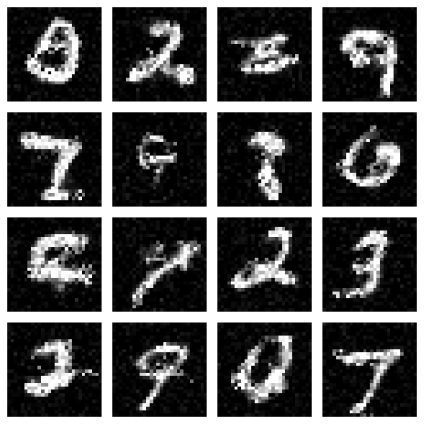

In [29]:
# Custom function to show images in a grid
def show_imgs(imgs, rows=10, cols=5):
    imgs = imgs.detach().cpu()
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5))
    for i, ax in enumerate(axes.flat):
        if i < imgs.size(0):
            ax.imshow(imgs[i][0], cmap='gray')
            ax.axis('off')
    plt.tight_layout()
    plt.show()

# Part 2: Sampling and Visualizations
@torch.no_grad()
def sample(model, num_samples=50):
    model.eval()
    z = torch.randn(num_samples, 784).to(device)
    x_gen = model.inverse(z)
    x_gen = x_gen.view(-1, 1, 28, 28).clamp(0, 1)
    show_imgs(x_gen, rows=4, cols=4)

@torch.no_grad()
def visualize_flow_transforms(model, num_samples=10):
    model.eval()
    z = torch.randn(num_samples, 784).to(device)
    all_outputs = model.inverse(z, return_all=True)
    selected = [0, 1, 2, 3, 4, 5]  # select 6 stages including final output
    imgs = [all_outputs[i].view(-1, 1, 28, 28).cpu() for i in selected]
    imgs = torch.cat(imgs, dim=0)
    show_imgs(imgs, rows=6, cols=num_samples)

# Generate new images after training
sample(model, num_samples=16)


In [28]:
# Test loop
model.eval()
final_loss = model.test_step(test_loader)
print(f"Final ELBO: {final_loss}")

# Save the model
#torch.save(model.state_dict(), 'vae_model.pth')

  0%|          | 0/79 [00:00<?, ?it/s]

Final ELBO: -1278.9065296800832


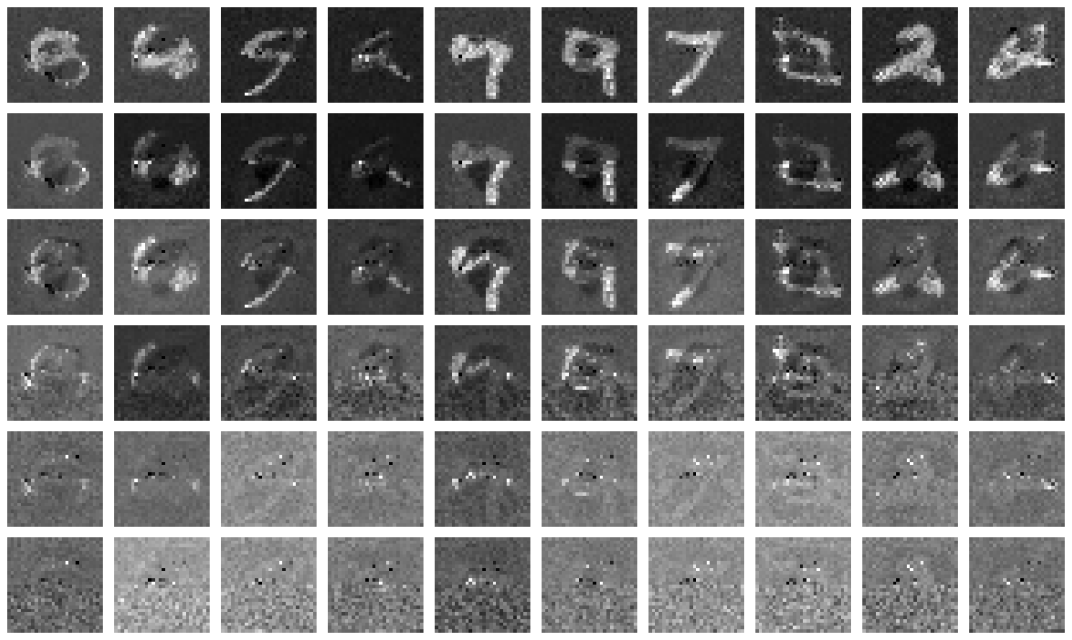

In [32]:
# Show intermediate outputs (z -> x) through flow layers
visualize_flow_transforms(model, num_samples=10)

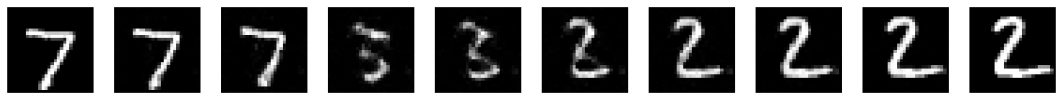

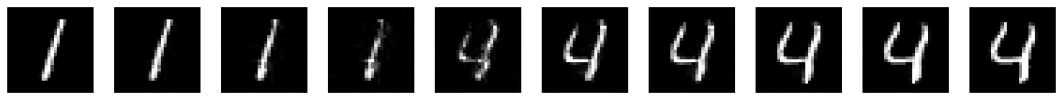

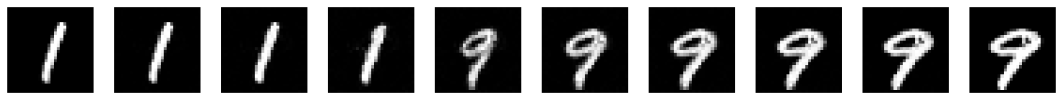

In [23]:
# Part 3: Latent Space Interpolation
@torch.no_grad()
def interpolate_latent(model, dataset, idx1, idx2, num_points=10):
    model.eval()

    # get 2 images from dataset
    img1, _ = dataset[idx1]
    img2, _ = dataset[idx2]
    img1 = img1.view(1, -1).to(device)
    img2 = img2.view(1, -1).to(device)

    # encode to z (use forward)
    z1, _ = model.forward(img1)
    z2, _ = model.forward(img2)

    # build 10 z points between z1 and z2
    z_points = [z1 * (1 - alpha) + z2 * alpha for alpha in torch.linspace(0, 1, num_points).to(device)]

    # decode z -> x (use inverse)
    x_recons = [model.inverse(z) for z in z_points]

    # reshape for display
    x_recons = torch.cat(x_recons, dim=0).view(-1, 1, 28, 28).clamp(0, 1)

    # show images
    show_imgs(x_recons,1, 10)


interpolate_latent(model, test_set, 0, 1)  # 7 to 2
interpolate_latent(model, test_set, 2, 4)  # 1 to 4
interpolate_latent(model, test_set, 5, 9)  # 1 to 9


  0%|          | 0/79 [00:00<?, ?it/s]

Final ELBO: -1278.8268


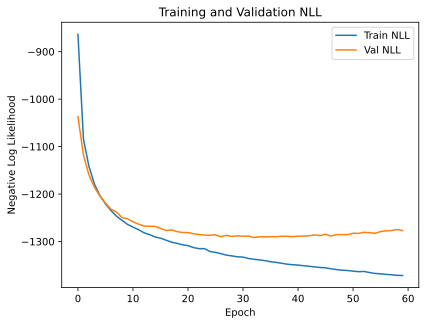

In [24]:
# Final evaluation and save
final_loss = model.test_step(test_loader)
print(f"Final ELBO: {final_loss:.4f}")

torch.save(model.state_dict(), "nf_model.pth")

train_nll_per_epoch = [
    torch.tensor(model.logs['train_nll'][i*390:(i+1)*390]).cpu().mean().item()
    for i in range(len(model.logs['val_loss']))
]
plt.plot(train_nll_per_epoch, label='Train NLL')
plt.plot(model.logs['val_loss'], label='Val NLL')
plt.xlabel('Epoch')
plt.ylabel('Negative Log Likelihood')
plt.title('Training and Validation NLL')
plt.legend()
plt.show()